# Análisis y preparación de AI4I 2020

Este notebook desarrolla la revisión de datos para el apartado III del informe. Conserva el CSV original, audita su calidad y prepara particiones reproducibles. **No entrena clasificadores ni calcula resultados predictivos.**

Ejecutar todas las celdas en orden con el entorno `.venv` del proyecto. Las rutas funcionan desde la raíz o desde `notebooks/`.

Fuente: [UCI AI4I 2020](https://doi.org/10.24432/C5HS5C). Datos sintéticos; la etiqueta describe falla en la observación, no tiempo restante hasta una avería.


In [1]:
from pathlib import Path
import sys
import json
import hashlib
from importlib.metadata import version

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data/raw/ai4i2020.csv').exists() and (p / 'src/preparation.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Abrir el notebook dentro de la carpeta del repositorio con data/ y src/.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from src.preparation import (
    FEATURES, NUMERIC_FEATURES, CATEGORICAL_FEATURES, TARGET, FAILURE_FLAGS,
    EXCLUDED, SEED, TEST_SIZE, N_FOLDS, load_dataset, audit_dataset,
    make_partitions, make_preprocessor, partition_summary,
)

REPORTS = ROOT / 'reports'
PROCESSED = ROOT / 'data/processed'
OUTPUTS = ROOT / 'outputs'
for folder in [REPORTS, PROCESSED, OUTPUTS]:
    folder.mkdir(parents=True, exist_ok=True)
versions = {name: version(name) for name in ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'nbformat', 'nbclient', 'ipykernel']}
display(pd.Series(versions, name='version'))
print('Semilla:', SEED)


pandas           3.0.1
numpy            2.3.5
scikit-learn     1.9.1
matplotlib      3.11.2
nbformat        5.11.1
nbclient        0.11.0
ipykernel        7.4.0
Name: version, dtype: str

Semilla: 42


## 3.1 Datos y variables

Las seis entradas son el tipo de producto y cinco mediciones. `UDI` y `Product ID` sirven para identificación. `Machine failure` es la salida binaria. TWF, HDF, PWF, OSF y RNF son indicadores de tipos de falla: no deben incorporarse al modelo porque contienen información de la respuesta.

Las temperaturas están en kelvin, la velocidad en rpm, el torque en Nm y el desgaste en minutos de uso de herramienta. El tipo L/M/H corresponde al producto, no a una categoría de salud de la máquina.


In [2]:
df = load_dataset(ROOT / 'data/raw/ai4i2020.csv')
quality, disagreements = audit_dataset(df)
display(df.head())
display(pd.DataFrame({'variable': df.columns, 'tipo': df.dtypes.astype(str).values,
                      'ausentes': df.isna().sum().values}))
print('Dimensiones:', df.shape)
print('SHA-256 original verificado:', quality['sha256'])


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


,variable,tipo,ausentes
0,UDI,int64,0
1,Product ID,str,0
2,Type,str,0
3,Air temperature [K],float64,0
4,Process temperature [K],float64,0
5,Rotational speed [rpm],int64,0
6,Torque [Nm],float64,0
7,Tool wear [min],int64,0
8,Machine failure,int64,0
9,TWF,int64,0


Dimensiones: (10000, 14)
SHA-256 original verificado: dc6630cd9b1f0f853922fad78a1b6436570d3f1ec863f1dd5c4340ac56bc8a8e


In [3]:
roles = []
for column in df.columns:
    role = ('entrada' if column in FEATURES else 'salida principal' if column == TARGET
            else 'identificador excluido' if column in ['UDI', 'Product ID']
            else 'etiqueta auxiliar excluida')
    roles.append({'variable': column, 'uso': role})
display(pd.DataFrame(roles))
class_counts = df[TARGET].value_counts().sort_index()
display(pd.DataFrame({'registros': class_counts, 'porcentaje': (class_counts / len(df) * 100).round(2)}))


,variable,uso
0,UDI,identificador excluido
1,Product ID,identificador excluido
2,Type,entrada
3,Air temperature [K],entrada
4,Process temperature [K],entrada
5,Rotational speed [rpm],entrada
6,Torque [Nm],entrada
7,Tool wear [min],entrada
8,Machine failure,salida principal
9,TWF,etiqueta auxiliar excluida


,registros,porcentaje
Machine failure,,
0,9661,96.61
1,339,3.39


### Figura 1 para el informe

La distribución completa de la etiqueta se usa para describir el dataset. Se muestran únicamente los conteos de clase, sin calcular rendimiento de modelos ni explorar relaciones predictivas en prueba. La imagen se exporta directamente desde estas cantidades verificadas.

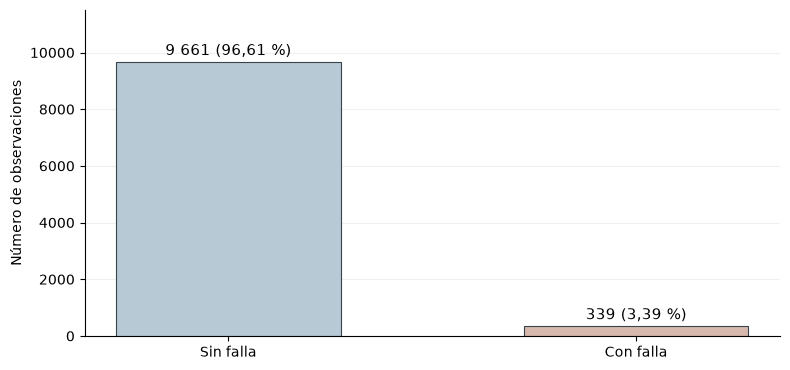

In [4]:
counts_all = df[TARGET].value_counts().reindex([0, 1], fill_value=0)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(['Sin falla', 'Con falla'], counts_all.values,
       color=['#B8C9D6', '#D7B8AC'], edgecolor='#37434D', linewidth=0.8, width=0.55)
ax.set_ylim(0, len(df) * 1.15)
ax.set_ylabel('Número de observaciones')
ax.spines[['top', 'right']].set_visible(False)
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=0.18)
for index, count in enumerate(counts_all):
    label = f'{count:,}'.replace(',', ' ') + f' ({100 * count / len(df):.2f} %)'.replace('.', ',')
    ax.text(index, count + len(df) * 0.025, label, ha='center', fontsize=11, color='black')
fig.tight_layout()
fig.savefig(OUTPUTS / 'figura_01_distribucion_dataset.png', dpi=220, bbox_inches='tight', facecolor='white')
plt.show()
assert int(counts_all.sum()) == len(df)

## 3.2 Calidad y política de preparación

Se verifican ausentes, valores no finitos, dominios válidos, identificadores únicos y duplicados. No se eliminan observaciones por tener mediciones extremas: podrían representar precisamente una falla. La copia revisada no necesita imputación.

La etiqueta principal se conserva tal como la publica la fuente. Auditamos su concordancia con los indicadores auxiliares; una discrepancia no se resuelve inventando una nueva etiqueta. Esta limitación quedará registrada.


In [5]:
display(pd.Series(quality, name='resultado').drop(['sha256', 'target_counts', 'label_policy']))
display(disagreements)
assert quality['rows'] == 10000
assert quality['missing_cells'] == 0
assert quality['duplicate_rows'] == 0
assert quality['duplicate_feature_vectors'] == 0
assert set(FEATURES).isdisjoint(EXCLUDED)
print('Política:', quality['label_policy'])


rows                         10000
columns                         14
missing_cells                    0
duplicate_rows                   0
duplicate_feature_vectors        0
target_flag_disagreements       27
failure_without_flag             9
flag_without_failure            18
Name: resultado, dtype: object

,UDI,Machine failure,TWF,HDF,PWF,OSF,RNF
1221,1222,0,0,0,0,0,1
1302,1303,0,0,0,0,0,1
1437,1438,1,0,0,0,0,0
1748,1749,0,0,0,0,0,1
2072,2073,0,0,0,0,0,1
2559,2560,0,0,0,0,0,1
2749,2750,1,0,0,0,0,0
3065,3066,0,0,0,0,0,1
3452,3453,0,0,0,0,0,1
4044,4045,1,0,0,0,0,0


Política: Conservar Machine failure; documentar discrepancias; no usar indicadores de falla como entradas.


### Hallazgo de etiquetas

El CSV contiene discrepancias entre `Machine failure` y la presencia de al menos un indicador de falla. Conservamos todas las filas y mantenemos `Machine failure` como verdad de referencia del experimento. Los resultados futuros medirán concordancia con esta etiqueta; no demostrarán una detección perfecta de todos los mecanismos físicos ni resolverán el ruido de etiquetado.


## 3.3 Entrenamiento, prueba y validación cruzada

Se reserva **20 % para prueba final**. El **80 % restante es desarrollo**, donde se aplicará validación cruzada estratificada de cinco pliegues. En cada iteración se usan cuatro pliegues para entrenar y uno para validar; no existe además un conjunto fijo de validación del 16 %.

La semilla es 42. Las proporciones de clase se preservan aproximadamente, con el redondeo que exige un número entero de casos. Los identificadores no se comparten entre desarrollo y prueba.

El muestreo aleatorio evalúa observaciones del mismo conjunto sintético. No es una evaluación temporal ni demuestra generalización a máquinas de otra fábrica. Las distribuciones y gráficos exploratorios siguientes se calculan solo en desarrollo; prueba queda reservada para el final.


In [6]:
development, test, folds = make_partitions(df)
summary = partition_summary(development, test, folds)
display(summary)
assert len(development) == 8000 and len(test) == 2000
assert len(folds) == len(development)
assert len(set(development['UDI']) & set(test['UDI'])) == 0
# Repetir la partición debe producir las mismas filas y pliegues.
dev_again, test_again, folds_again = make_partitions(df)
pd.testing.assert_frame_equal(development, dev_again)
pd.testing.assert_frame_equal(test, test_again)
pd.testing.assert_frame_equal(folds, folds_again)
print('Cobertura, separación y reproducibilidad comprobadas.')


,partition,rows,no_failure,failure,failure_percent
0,development,8000,7729,271,3.3875
1,test,2000,1932,68,3.4000
2,cv_1_train,6400,6183,217,3.3906
3,cv_1_validation,1600,1546,54,3.3750
4,cv_2_train,6400,6183,217,3.3906
5,cv_2_validation,1600,1546,54,3.3750
6,cv_3_train,6400,6183,217,3.3906
7,cv_3_validation,1600,1546,54,3.3750
8,cv_4_train,6400,6183,217,3.3906
9,cv_4_validation,1600,1546,54,3.3750


Cobertura, separación y reproducibilidad comprobadas.


### Figura 2 para el informe

El diagrama utiliza los tamaños de las particiones y del archivo de pliegues generados arriba. Las cinco columnas representan bloques de desarrollo; en cada iteración cambia el bloque de validación. La reserva de prueba queda fuera de los cinco pliegues. No se representan resultados de clasificadores.

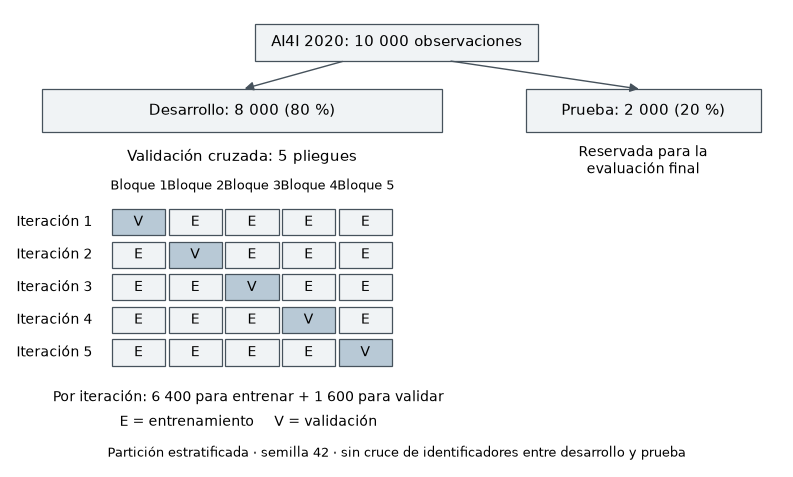

In [7]:
from matplotlib.patches import Rectangle, FancyArrowPatch

fig, ax = plt.subplots(figsize=(8.0, 4.8))
ax.set_xlim(0, 12)
ax.set_ylim(0, 8.0)
ax.axis('off')

def box(x, y, width, height, text, fill='#F0F3F5', fontsize=11):
    ax.add_patch(Rectangle((x, y), width, height, facecolor=fill,
                           edgecolor='#46525C', linewidth=0.9))
    ax.text(x + width / 2, y + height / 2, text, ha='center', va='center',
            fontsize=fontsize, color='black')

def arrow(start, end):
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle='-|>', mutation_scale=13,
                                linewidth=1, color='#46525C'))

def fmt(value):
    return f'{value:,}'.replace(',', ' ')

box(3.8, 7.1, 4.4, 0.65, f'AI4I 2020: {fmt(len(df))} observaciones')
box(0.5, 5.85, 6.2, 0.75, f'Desarrollo: {fmt(len(development))} ({100 * len(development) / len(df):.0f} %)')
box(8.0, 5.85, 3.65, 0.75, f'Prueba: {fmt(len(test))} ({100 * len(test) / len(df):.0f} %)')
arrow((5.2, 7.1), (3.6, 6.6))
arrow((6.8, 7.1), (9.8, 6.6))
ax.text(9.825, 5.35, 'Reservada para la\nevaluación final', ha='center', va='center', fontsize=10, color='black')
ax.text(3.6, 5.35, f'Validación cruzada: {N_FOLDS} pliegues', ha='center', fontsize=11, color='black')

fold_counts = folds['validation_fold'].value_counts().sort_index()
assert fold_counts.nunique() == 1
fold_size = int(fold_counts.iloc[0])
for col in range(N_FOLDS):
    ax.text(2.0 + col * 0.88, 4.85, f'Bloque {col + 1}', ha='center', fontsize=9, color='black')
for row in range(N_FOLDS):
    y = 4.05 - row * 0.57
    ax.text(0.1, y + 0.23, f'Iteración {row + 1}', va='center', fontsize=10, color='black')
    for col in range(N_FOLDS):
        is_validation = row == col
        box(1.58 + col * 0.88, y, 0.83, 0.46, 'V' if is_validation else 'E',
            '#B8C9D6' if is_validation else '#F0F3F5', fontsize=10)
ax.text(3.7, 1.15, f'Por iteración: {fmt(len(development) - fold_size)} para entrenar + {fmt(fold_size)} para validar',
        ha='center', fontsize=10, color='black')
ax.text(3.7, 0.72, 'E = entrenamiento     V = validación', ha='center', fontsize=10, color='black')
ax.text(6.0, 0.18, 'Partición estratificada · semilla 42 · sin cruce de identificadores entre desarrollo y prueba',
        ha='center', fontsize=9, color='black')
fig.tight_layout(pad=0.8)
fig.savefig(OUTPUTS / 'figura_02_particion_validacion.png', dpi=220, bbox_inches='tight', facecolor='white')
plt.show()

,count,mean,std,min,25%,50%,75%,max
Air temperature [K],8000.0,300.005450,1.996844,295.3,298.3,300.1,301.5,304.5
Process temperature [K],8000.0,310.006062,1.479432,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],8000.0,1539.356875,180.982943,1168.0,1422.0,1503.0,1613.0,2886.0
Torque [Nm],8000.0,40.003363,10.019546,3.8,33.2,40.1,46.8,76.6
Tool wear [min],8000.0,107.685000,63.612002,0.0,53.0,107.0,163.0,253.0


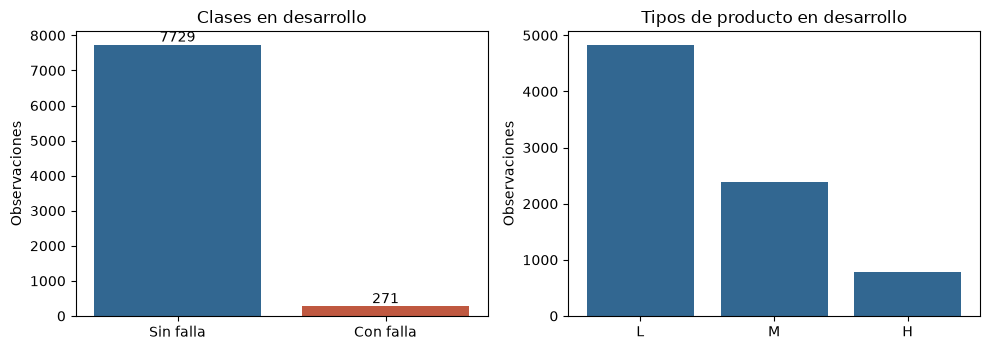

In [8]:
display(development[NUMERIC_FEATURES].describe().T)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
counts = development[TARGET].value_counts().sort_index()
axes[0].bar(['Sin falla', 'Con falla'], counts.values, color=['#326791', '#bf5840'])
axes[0].set_ylabel('Observaciones')
axes[0].set_title('Clases en desarrollo')
for i, value in enumerate(counts.values):
    axes[0].text(i, value, str(value), ha='center', va='bottom')
types = development['Type'].value_counts().reindex(['L', 'M', 'H'])
axes[1].bar(types.index, types.values, color='#326791')
axes[1].set_title('Tipos de producto en desarrollo')
axes[1].set_ylabel('Observaciones')
fig.tight_layout()
fig.savefig(OUTPUTS / 'distribuciones_desarrollo.png', dpi=160)
plt.show()


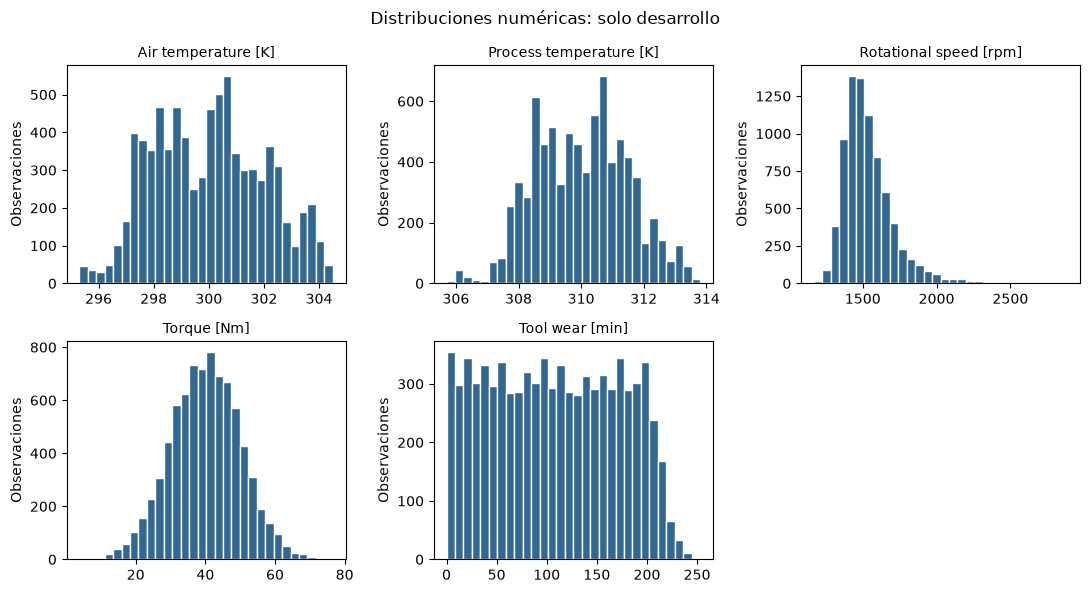

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for ax, column in zip(axes.flat, NUMERIC_FEATURES):
    ax.hist(development[column], bins=30, color='#326791', edgecolor='white')
    ax.set_title(column, fontsize=10)
    ax.set_ylabel('Observaciones')
axes.flat[-1].axis('off')
fig.suptitle('Distribuciones numéricas: solo desarrollo')
fig.tight_layout()
fig.savefig(OUTPUTS / 'mediciones_desarrollo.png', dpi=160)
plt.show()


## Codificación y escalamiento sin fuga de información

El tipo de producto se codifica con one-hot encoding. La regresión logística tendrá escalamiento estándar de las variables numéricas; los árboles y Random Forest conservarán sus escalas originales.

`make_preprocessor` devuelve un transformador nuevo y sin ajustar. En el entrenamiento posterior se integrará dentro de un `Pipeline` con el clasificador para que cada pliegue aprenda sus propias transformaciones.

La comprobación siguiente usa solo el entrenamiento del primer pliegue para ajustar y su validación para transformar. No se ajusta un preprocesador global antes de la validación cruzada ni se transforma el conjunto de prueba en esta etapa.


In [10]:
is_validation = folds['validation_fold'].eq(1)
X_train_fold = development.loc[~is_validation, FEATURES]
X_validation_fold = development.loc[is_validation, FEATURES]

scaled = make_preprocessor(scale_numeric=True)
X_train_scaled = scaled.fit_transform(X_train_fold)
X_validation_scaled = scaled.transform(X_validation_fold)
unscaled = make_preprocessor(scale_numeric=False)
X_train_unscaled = unscaled.fit_transform(X_train_fold)
X_validation_unscaled = unscaled.transform(X_validation_fold)

assert np.isfinite(X_train_scaled).all() and np.isfinite(X_validation_scaled).all()
assert X_train_scaled.shape[1] == 8
assert X_train_unscaled.shape == X_train_scaled.shape
np.testing.assert_allclose(scaled.named_transformers_['numeric'].mean_,
                           X_train_fold[NUMERIC_FEATURES].mean().to_numpy())
np.testing.assert_allclose(X_train_scaled[:, :5].mean(axis=0), 0, atol=1e-10)
np.testing.assert_allclose(X_train_unscaled[:, :5], X_train_fold[NUMERIC_FEATURES].to_numpy())
assert not hasattr(make_preprocessor(True), 'transformers_')

print('Entrenamiento del primer pliegue:', X_train_scaled.shape)
print('Validación del primer pliegue:', X_validation_scaled.shape)
display(pd.DataFrame(X_train_scaled[:5], columns=scaled.get_feature_names_out()))
print('Comprobación completa. No se entrenó ningún clasificador.')


Entrenamiento del primer pliegue: (6400, 8)
Validación del primer pliegue: (1600, 8)


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_H,Type_L,Type_M
0,0.999565,0.601986,-0.470486,0.732793,-0.847647,0.0,0.0,1.0
1,-1.505257,-1.151115,-0.785302,0.652598,0.376293,0.0,0.0,1.0
2,0.498600,1.073974,-1.017272,0.572402,0.454751,0.0,0.0,1.0
3,-1.455160,-1.016261,1.059410,-1.121729,-0.910414,0.0,1.0,0.0
4,-0.854003,-0.746553,0.910286,-0.810971,-1.569458,1.0,0.0,0.0


Comprobación completa. No se entrenó ningún clasificador.


## Archivos reproducibles

Se exportan las particiones sin escalar: UDI se conserva para trazabilidad, nunca como entrada. Los cinco indicadores auxiliares quedan fuera de estos archivos. El archivo de pliegues indica en qué iteración una observación de desarrollo actuará como validación.

Los CSV preparados y las imágenes son salidas regenerables y quedan excluidos de Git. Los resúmenes pequeños de auditoría y partición sí se versionan, junto con este notebook ejecutado.


In [11]:
export_columns = ['UDI'] + FEATURES + [TARGET]
development[export_columns].to_csv(PROCESSED / 'development.csv', index=False)
test[export_columns].to_csv(PROCESSED / 'test.csv', index=False)
folds.to_csv(PROCESSED / 'cv_folds.csv', index=False)

def id_hash(series):
    return hashlib.sha256(','.join(map(str, series)).encode('ascii')).hexdigest()

preparation = {
    'seed': SEED, 'test_fraction': TEST_SIZE, 'cv_folds': N_FOLDS,
    'features': FEATURES, 'target': TARGET, 'excluded_inputs': EXCLUDED,
    'development_id_sha256': id_hash(development['UDI']),
    'test_id_sha256': id_hash(test['UDI']),
    'split_policy': '80% desarrollo con CV estratificada de 5 pliegues; 20% prueba final aislada.',
    'preprocessing_policy': 'Ajustar codificación y escalamiento dentro de cada pipeline/pliegue; no reutilizar el ejemplo ajustado.',
    'scope': 'Clasificación binaria en datos sintéticos; sin pronóstico temporal ni validación externa.',
    'versions': versions,
}
(REPORTS / 'quality_summary.json').write_text(json.dumps(quality, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
(REPORTS / 'preparation_summary.json').write_text(json.dumps(preparation, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
summary.to_csv(REPORTS / 'partition_summary.csv', index=False)
disagreements.to_csv(REPORTS / 'label_disagreements.csv', index=False)
assert hashlib.sha256((ROOT / 'data/raw/ai4i2020.csv').read_bytes()).hexdigest() == quality['sha256']
print('Guardados: particiones, pliegues, auditoría y resúmenes. CSV original intacto.')


Guardados: particiones, pliegues, auditoría y resúmenes. CSV original intacto.


## Conclusiones de esta etapa

- Se conserva el dataset original con sus 10 000 registros y las etiquetas publicadas.
- Se documentan la baja frecuencia de fallas y las discrepancias entre etiquetas.
- Desarrollo y prueba están separados; los pliegues se definen solo dentro de desarrollo.
- Las transformaciones son específicas del modelo y se ajustarán dentro de cada entrenamiento.
- La siguiente etapa será comparar clasificadores. Aún no hay métricas de detección, modelo seleccionado ni simulación implementada.

## Fuentes técnicas

- [Dataset AI4I 2020, UCI](https://doi.org/10.24432/C5HS5C).
- [Scikit-learn: prevención de fuga de información](https://scikit-learn.org/stable/common_pitfalls.html).
- [Scikit-learn: partición estratificada](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html).
- [Scikit-learn: validación cruzada](https://scikit-learn.org/stable/modules/cross_validation.html).
